# Cached CLIP features — load and sanity-check

Loads the git-ignored feature cache at `cache/features/` (produced by `real/modal_extract.py`, consumed by `real/head.py` / `real/audit.py`).

Run this notebook with cwd = `REACH_AISTATS/`. Local copy note: several CIFAR-10-C files were truncated during `modal volume get` and are listed by the inventory cell; the intact copies live on the Modal volume `reach-aistats`.

In [1]:
from pathlib import Path
import numpy as np

FEATURES = Path('cache/features')
intact, broken = {}, []
for f in sorted(FEATURES.glob('*.npz')):
    mb = f.stat().st_size / 1e6
    try:
        with np.load(f, allow_pickle=False) as d:
            spec = {k: f'{d[k].shape} {d[k].dtype}' for k in d.files}
        intact[f.stem] = spec
        print(f'{f.name:38s} {mb:7.1f} MB  OK   {spec}')
    except Exception as e:
        broken.append(f.stem)
        print(f'{f.name:38s} {mb:7.1f} MB  BAD  ({type(e).__name__})')
print(f'\nintact {len(intact)}/{len(intact) + len(broken)}; broken: {broken}')

cifar10_test.npz                          10.3 MB  OK   {'X': '(10000, 512) float16', 'y': '(10000,) int16'}
cifar10_train.npz                         51.3 MB  OK   {'X': '(50000, 512) float16', 'y': '(50000,) int16'}
cifar10c_brightness.npz                   51.4 MB  OK   {'X': '(50000, 512) float16', 'y': '(50000,) int16', 'severity': '(50000,) int8'}
cifar10c_contrast.npz                     51.4 MB  OK   {'X': '(50000, 512) float16', 'y': '(50000,) int16', 'severity': '(50000,) int8'}
cifar10c_defocus_blur.npz                 51.4 MB  BAD  (BadZipFile)
cifar10c_elastic_transform.npz            51.0 MB  BAD  (BadZipFile)
cifar10c_fog.npz                          51.1 MB  BAD  (BadZipFile)
cifar10c_frost.npz                        50.9 MB  BAD  (BadZipFile)
cifar10c_gaussian_noise.npz               51.0 MB  BAD  (BadZipFile)
cifar10c_glass_blur.npz                   51.2 MB  BAD  (BadZipFile)
cifar10c_impulse_noise.npz                51.1 MB  BAD  (BadZipFile)
cifar10c_jpeg_compressi

In [2]:
from real.head import load  # same loader real/audit.py uses; resolves cache/features

train, test = load('cifar10_train'), load('cifar10_test')
for name, d in [('cifar10_train', train), ('cifar10_test', test)]:
    X, y = d['X'], d['y']
    print(f'{name}: X {X.shape} {X.dtype} ({X.nbytes / 1e6:.0f} MB), y {y.shape} {y.dtype}, '
          f'labels {y.min()}..{y.max()}, per-class {np.bincount(y, minlength=10).tolist()}')

cifar10_train: X (50000, 512) float16 (51 MB), y (50000,) int16, labels 0..9, per-class [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
cifar10_test: X (10000, 512) float16 (10 MB), y (10000,) int16, labels 0..9, per-class [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


In [3]:
for name in sorted(k for k in intact if k.startswith('cifar10c_')):
    d = load(name)
    X, y, sev = d['X'], d['y'], d['severity']
    assert X.shape[0] == y.shape[0] == sev.shape[0] == 50000, name
    counts = np.bincount(sev, minlength=6)[1:]  # severities 1..5, 10k each
    print(f'{name}: X {X.shape}, severity counts {counts.tolist()}')

cifar10c_brightness: X (50000, 512), severity counts [10000, 10000, 10000, 10000, 10000]
cifar10c_contrast: X (50000, 512), severity counts [10000, 10000, 10000, 10000, 10000]
cifar10c_shot_noise: X (50000, 512), severity counts [10000, 10000, 10000, 10000, 10000]


In [4]:
X = train['X'].astype(np.float32)  # fp16 storage; cast for the math
norms = np.linalg.norm(X, axis=1)
print(f'row-norm: mean {norms.mean():.2f}, std {norms.std():.2f}, range [{norms.min():.2f}, {norms.max():.2f}]')
per_class = [norms[train['y'] == c].mean() for c in range(10)]
print('mean row-norm per class:', ' '.join(f'{v:.1f}' for v in per_class))

row-norm: mean 1.00, std 0.00, range [1.00, 1.00]
mean row-norm per class: 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0


## Schema and re-fetching

Per `real/modal_extract.py`: every file has `X` (N x 512 CLIP ViT-B/32, float16) and `y` (int16). CIFAR-10-C files add `severity` (int8, 5 x 10 000 rows); CIFAR-100 files add `y_coarse`.

Broken local files are truncated downloads — the volume copies are intact (the paper's corruption results were computed on Modal). To refresh locally:

```bash
modal run real/modal_extract.py            # re-extract next to the volume
modal volume get reach-aistats features cache/features/   # slow from this machine (~5 min / 50 MB)
```

## Disjoint pools (`data.pools`)

`data/pools.py` builds the four pools the pipeline needs, with disjointness by construction:

- `dev` — first 10 000 of a seeded train permutation (head fitting, as `real/audit.py`)
- `reference` — the labelled set: the rest of the permutation, optionally m per class
- `log` — the **first half** of the test pool by image index (or the CIFAR-10-C rows aligned to those indices at a given severity)
- `eval` — the **second half**, always clean test images

The log and eval halves share no image, so no deployment image is ever scored against itself. Corruption logs reuse the log half's indices, and the loader verifies the corruption file's labels agree with the test pool on every shared row before using it.

In [5]:
from data.pools import load_pools, check_disjoint

pools = load_pools(seed=0, m_per_class=200)   # 200 labelled images per class
for name, p in pools.items():
    print(f'{name:10s} n={len(p["index"]):6d}  from {p["pool"]}')
check_disjoint(pools)
print('\nlog ∩ eval images:', len(np.intersect1d(pools['log']['index'], pools['eval']['index'])))
print('log per-class:', np.bincount(pools['log']['y'], minlength=10).tolist())
print('eval per-class:', np.bincount(pools['eval']['y'], minlength=10).tolist())

dev        n= 10000  from cifar10_train
reference  n=  2000  from cifar10_train
log        n=  5000  from cifar10_test
eval       n=  5000  from cifar10_test

log ∩ eval images: 0
log per-class: [488, 505, 512, 497, 507, 488, 491, 495, 504, 513]
eval per-class: [512, 495, 488, 503, 493, 512, 509, 505, 496, 487]


In [6]:
# Corrupted log, same indices: brightness at severity 3 replaces the clean log rows,
# eval stays clean — disjointness is untouched because it is index-based.
shifted = load_pools(seed=0, m_per_class=200, corruption='brightness', severity=3)
check_disjoint(shifted)
same_idx = np.array_equal(shifted['log']['index'], pools['log']['index'])
moved = np.abs(shifted['log']['X'].astype(np.float32) - pools['log']['X'].astype(np.float32)).mean()
eval_unchanged = np.array_equal(shifted['eval']['X'], pools['eval']['X'])
print(f'same log indices: {same_idx}; eval rows unchanged: {eval_unchanged}')
print(f'mean |shift| per feature on the shared images: {moved:.4f} (0 would mean no corruption)')

same log indices: True; eval rows unchanged: True
mean |shift| per feature on the shared images: 0.0063 (0 would mean no corruption)


In [7]:
# Materialise the three sets (seed 0): labeled from train, unlabeled/test from the two
# disjoint halves of the test pool. Pairwise disjoint by construction — no shared image
# anywhere. Files land in cache/sets/ (git-ignored; re-run this cell to regenerate).
sets = load_pools(seed=0)   # m_per_class=None -> the full 40k labelled reference
out = Path('cache/sets'); out.mkdir(parents=True, exist_ok=True)
for name, key in [('labeled', 'reference'), ('unlabeled', 'log'), ('test', 'eval')]:
    p = sets[key]
    np.savez(out / f'{name}.npz', X=p['X'], y=p['y'], index=p['index'])
    print(f'{name:10s} {len(p["index"]):6d} images -> {out}/{name}.npz')
    print(f'           per-class {np.bincount(p["y"], minlength=10).tolist()}')

labeled     40000 images -> cache/sets/labeled.npz
           per-class [3971, 4002, 3976, 4025, 3970, 4032, 4023, 4008, 3983, 4010]
unlabeled    5000 images -> cache/sets/unlabeled.npz
           per-class [488, 505, 512, 497, 507, 488, 491, 495, 504, 513]
test         5000 images -> cache/sets/test.npz
           per-class [512, 495, 488, 503, 493, 512, 509, 505, 496, 487]


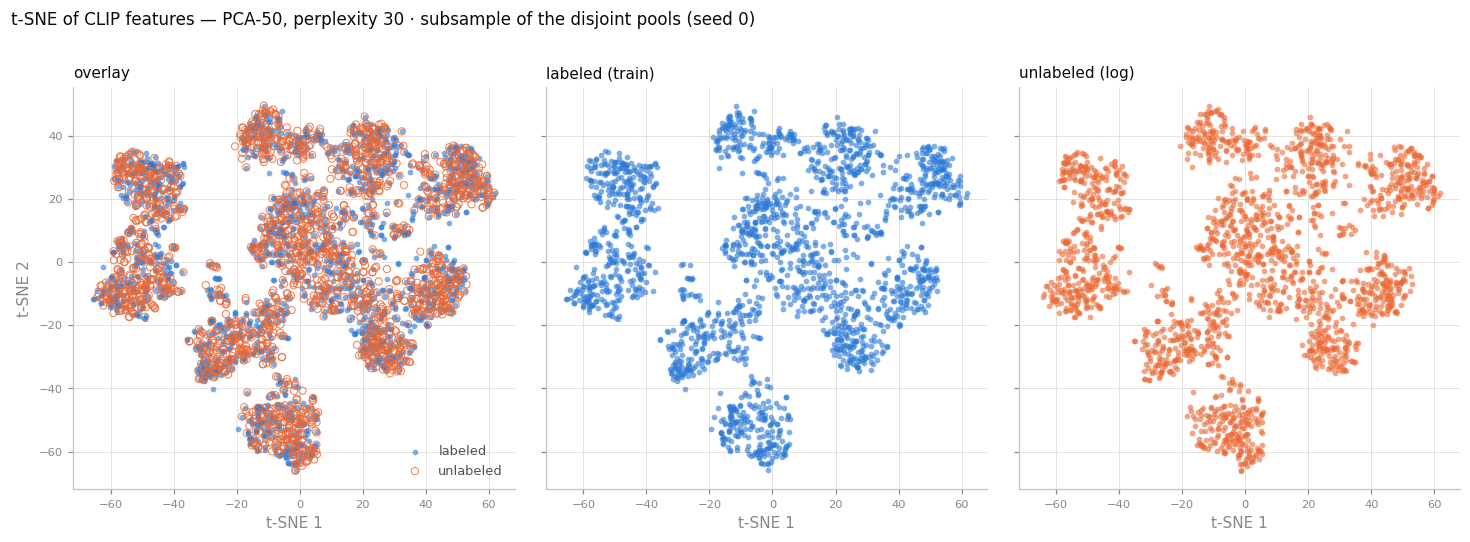

In [8]:
# t-SNE: do the unlabelled log images sit inside the labelled support?
# One shared embedding, shown three ways: overlay, labeled only, unlabeled only.
# Subsample for a readable embedding: 200 labeled per class + 2,000 unlabeled, seeded.
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

labeled = np.load('cache/sets/labeled.npz')
unlabeled = np.load('cache/sets/unlabeled.npz')
rng = np.random.default_rng(0)
lab = np.concatenate([rng.choice(np.flatnonzero(labeled['y'] == c), 200, replace=False)
                      for c in np.unique(labeled['y'])])
unl = rng.choice(len(unlabeled['y']), 2000, replace=False)
X = np.vstack([labeled['X'][lab], unlabeled['X'][unl]]).astype(np.float32)
emb = TSNE(n_components=2, init='pca', perplexity=30, random_state=0,
           ).fit_transform(PCA(n_components=50, random_state=0).fit_transform(X))
n_lab = len(lab)
BLUE, ORANGE = '#2a78d6', '#eb6834'   # validated categorical slots 1-2 (CVD dE 24.7)
INK, MUTED, GRID, AXIS = '#0b0b0b', '#898781', '#e1e0d9', '#c3c2b7'

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6), dpi=110, sharex=True, sharey=True)
specs = [('overlay', emb[:n_lab], emb[n_lab:]),
         ('labeled (train)', emb[:n_lab], None),
         ('unlabeled (log)', None, emb[n_lab:])]
for ax, (title, blue_pts, orange_pts) in zip(axes, specs):
    if blue_pts is not None:
        ax.scatter(blue_pts[:, 0], blue_pts[:, 1], s=14, c=BLUE, alpha=.6, lw=0, zorder=3,
                   label='labeled')
    if orange_pts is not None:
        if title == 'overlay':   # open rings: visible on top of the filled cloud
            ax.scatter(orange_pts[:, 0], orange_pts[:, 1], s=22, facecolors='none',
                       edgecolors=ORANGE, alpha=.8, lw=.7, zorder=4, label='unlabeled')
        else:
            ax.scatter(orange_pts[:, 0], orange_pts[:, 1], s=14, c=ORANGE, alpha=.6, lw=0, zorder=3)
    ax.set_title(title, color=INK, fontsize=10, loc='left')
    ax.grid(color=GRID, lw=.6, zorder=0)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=7.5)
    ax.set_aspect('equal')
    ax.set_xlabel('t-SNE 1', color=MUTED)
axes[0].set_ylabel('t-SNE 2', color=MUTED)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor='#52514e', loc='lower right')
fig.suptitle('t-SNE of CLIP features — PCA-50, perplexity 30 · subsample of the disjoint pools (seed 0)',
             x=.01, ha='left', color=INK, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, .93))
plt.show()

In [9]:
# How much do the two sets overlap? Quantified in the original 512-d space (t-SNE
# distances are not meaningful). If unlabeled points sit inside the labeled support,
# each unlabeled point's nearest labeled neighbour should be about as close as a
# labeled point's nearest other labeled point (leave-one-out baseline).
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(0)
lab_n = rng.choice(len(labeled['y']), 1000, replace=False)
unl_n = rng.choice(len(unlabeled['y']), 1000, replace=False)
L = labeled['X'][lab_n].astype(np.float32)
U = unlabeled['X'][unl_n].astype(np.float32)

d_unl = NearestNeighbors(n_neighbors=1).fit(L).kneighbors(U)[0].ravel()   # unlabeled -> nearest labeled
d_lab = NearestNeighbors(n_neighbors=2).fit(L).kneighbors(L)[0][:, 1]     # labeled -> nearest labeled (LOO)
cut = np.quantile(d_lab, .95)
print(f'nearest labeled neighbour: unlabeled median {np.median(d_unl):.4f} vs '
      f'labeled LOO median {np.median(d_lab):.4f}  (ratio {np.median(d_unl) / np.median(d_lab):.2f})')
print(f'unlabeled points inside the labeled 95% radius: {(d_unl <= cut).mean():.1%} '
      f'(labeled LOO itself: {(d_lab <= cut).mean():.1%})')
worst = np.unique(unlabeled['y'][unl_n][d_unl > cut], return_counts=True)
print('classes with points outside that radius:', dict(zip(worst[0].tolist(), worst[1].tolist())) or 'none')

nearest labeled neighbour: unlabeled median 0.3886 vs labeled LOO median 0.3890  (ratio 1.00)
unlabeled points inside the labeled 95% radius: 94.2% (labeled LOO itself: 95.0%)
classes with points outside that radius: {0: 18, 1: 6, 2: 2, 3: 3, 5: 3, 6: 1, 7: 1, 8: 8, 9: 16}


## Labeled classes 0–5 only, unlabeled all ten

Restricting the labeled set to classes 0–5 while the log keeps all ten creates the
**novel-mass scenario**: ~40% of unlabeled images belong to classes with no labeled
support (6–9). What to expect if the pipeline reads the pools honestly — and what
REACH's `W_unk` is for:

- t-SNE: orange rings on the six known clusters **plus orange-only islands** at 6–9
- nearest-labelled distances: ~1.00 ratio *within the known classes*, sharply above 1 *for the novel classes*

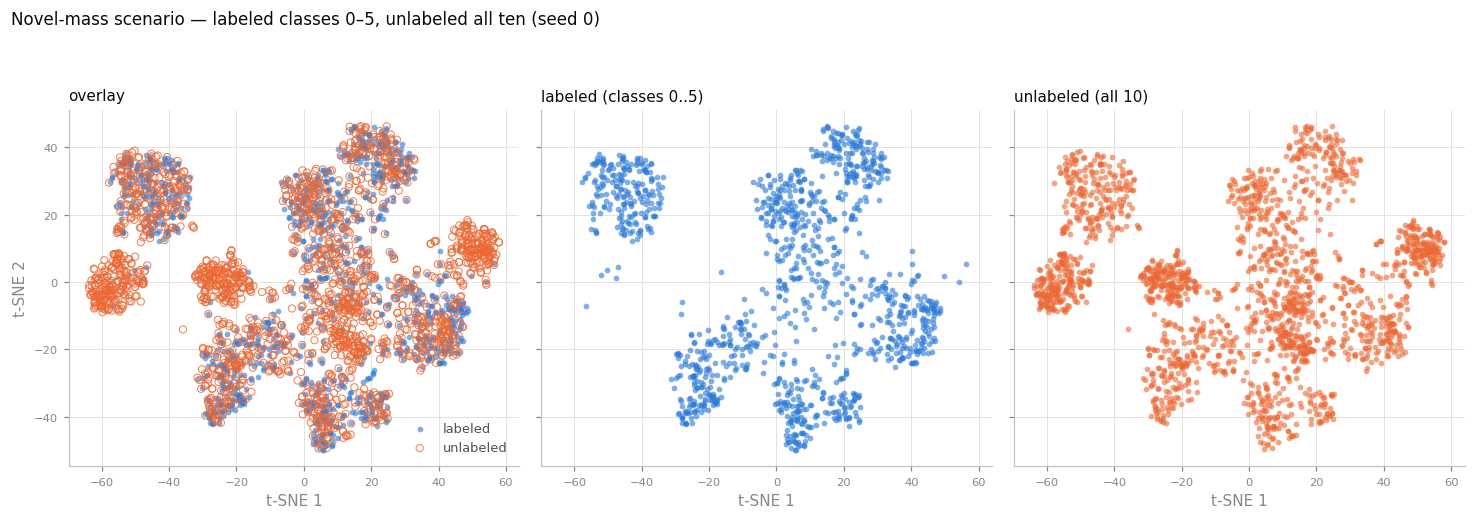

unlabeled subsample: 1204 from known classes, 796 from novel [6, 7, 8, 9]


In [10]:
# Novel-mass t-SNE: labeled = classes 0..5 only, unlabeled = all ten.
KNOWN = np.arange(6)          # labeled support; change to np.arange(5) for classes 0..4
NOVEL = np.arange(10)[6:]
lab_k = np.concatenate([rng.choice(np.flatnonzero(labeled['y'] == c), 200, replace=False)
                        for c in KNOWN])
unl_n = rng.choice(len(unlabeled['y']), 2000, replace=False)
Xk = np.vstack([labeled['X'][lab_k], unlabeled['X'][unl_n]]).astype(np.float32)
emb_k = TSNE(n_components=2, init='pca', perplexity=30, random_state=0,
             ).fit_transform(PCA(n_components=50, random_state=0).fit_transform(Xk))
n_lab_k = len(lab_k)
is_novel = np.isin(unlabeled['y'][unl_n], NOVEL)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6), dpi=110, sharex=True, sharey=True)
blue_pts, orange_pts = emb_k[:n_lab_k], emb_k[n_lab_k:]
for ax, (title, bp, op) in zip(axes, [('overlay', blue_pts, orange_pts),
                                      (f'labeled (classes {KNOWN[0]}..{KNOWN[-1]})', blue_pts, None),
                                      ('unlabeled (all 10)', None, orange_pts)]):
    if bp is not None:
        ax.scatter(bp[:, 0], bp[:, 1], s=14, c=BLUE, alpha=.6, lw=0, zorder=3, label='labeled')
    if op is not None:
        if title == 'overlay':
            ax.scatter(op[:, 0], op[:, 1], s=22, facecolors='none', edgecolors=ORANGE,
                       alpha=.8, lw=.7, zorder=4, label='unlabeled')
        else:
            ax.scatter(op[:, 0], op[:, 1], s=14, c=ORANGE, alpha=.6, lw=0, zorder=3)
    ax.set_title(title, color=INK, fontsize=10, loc='left')
    ax.grid(color=GRID, lw=.6, zorder=0)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=7.5)
    ax.set_aspect('equal')
    ax.set_xlabel('t-SNE 1', color=MUTED)
axes[0].set_ylabel('t-SNE 2', color=MUTED)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor='#52514e', loc='lower right')
fig.suptitle('Novel-mass scenario — labeled classes 0–5, unlabeled all ten (seed 0)',
             x=.01, ha='left', color=INK, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, .93))
plt.show()
print(f'unlabeled subsample: {int((~is_novel).sum())} from known classes, {int(is_novel.sum())} from novel {NOVEL.tolist()}')

In [11]:
# Same kNN overlap measures as above, now split by whether the unlabeled point's class
# has labeled support. This is the quantitative version of the islands.
Lk = labeled['X'][lab_k].astype(np.float32)
Uk = unlabeled['X'][unl_n].astype(np.float32)
d_unl_k = NearestNeighbors(n_neighbors=1).fit(Lk).kneighbors(Uk)[0].ravel()
d_lab_k = NearestNeighbors(n_neighbors=2).fit(Lk).kneighbors(Lk)[0][:, 1]
cut_k = np.quantile(d_lab_k, .95)
known_pts, novel_pts = d_unl_k[~is_novel], d_unl_k[is_novel]
print(f'labeled LOO median distance: {np.median(d_lab_k):.4f}')
print(f'known-class unlabeled: median {np.median(known_pts):.4f} '
      f'(ratio {np.median(known_pts) / np.median(d_lab_k):.2f}), '
      f'{(known_pts <= cut_k).mean():.1%} inside the 95% radius')
print(f'novel-class unlabeled: median {np.median(novel_pts):.4f} '
      f'(ratio {np.median(novel_pts) / np.median(d_lab_k):.2f}), '
      f'{(novel_pts <= cut_k).mean():.1%} inside the 95% radius')
print(f'naive novel-mass estimate from the radius rule: {(d_unl_k > cut_k).mean():.1%} '
      f'(true novel fraction in the subsample: {is_novel.mean():.1%})')

labeled LOO median distance: 0.3790
known-class unlabeled: median 0.3804 (ratio 1.00), 94.6% inside the 95% radius
novel-class unlabeled: median 0.4830 (ratio 1.27), 44.5% inside the 95% radius
naive novel-mass estimate from the radius rule: 25.4% (true novel fraction in the subsample: 39.8%)


## Controlled-source factorial — 5 known classes, novel inside the log support

Setup: labeled classes **0–4** only; deployment (log) restricted to the log half of the test pool; eval on the disjoint eval half. One knob at a time around BASE (n=1000, m=20, η=0), 5 seeds, both novel arms per the review: **δ ∈ {0, 0.05, 0.2}** run explicitly (δ=0 = success case, δ>0 = stated-limit case).

| Knob | Grid | Isolates | Ground truth |
|---|---|---|---|
| n (unlabelled) | 10², 10³, 10⁴ | prevalence part | Dirichlet(1) log prevalences, fresh per seed |
| m (labels/class) | 5, 20, 100 | label part + conditional bias | true per-class cell conditionals |
| δ (novel mass) | 0, 0.05, 0.2 | coverage part | which classes carry it and how much |
| η (label noise) | 0, 0.1, 0.2 | nuisance control | injected flip rate |

Machinery: `real.audit.build_context` / `run_cell` (the paper's engine — exact L2 ball, oracle q, paired draws), not a parallel implementation. New here: the 5-known regime, the trap readout at on-support cells, and the excess-risk / n\* metric.

In [12]:
# PRE-REGISTERED PREDICTIONS — this cell runs before any result cell below.
# Expected direction per knob; the trap gets two explicit alternatives to decide between.
import hashlib, json

PREDICTIONS = {
    'n_up': {
        'W_cls': 'falls (prevalence variance ~ 1/sqrt(n))',
        'W_label': 'flat (fixed anchor, exact in n by construction)',
        'W_unk_joint': 'falls toward truth IF novel separable; stays wide if novel mass sits inside the known hull (THE TRAP)',
    },
    'm_up': {
        'W_cls': 'falls (conditional estimates sharpen)',
        'W_label': 'falls (label channel tightens)',
        'W_unk_joint': 'flat (novel row comes from the novel ref pool, not from m)',
    },
    'delta_up': {
        'W_unk_joint': 'grows (more mass the interval must absorb)',
        'W_cls': 'flat to mild growth (radius grows with the log)',
        'W_label': 'flat',
    },
    'eta_up': {
        'W_label': 'grows (noisier label channel)',
        'W_cls': 'mild growth (debias radius cross-loads, README: report cross-effects)',
        'W_unk_joint': 'flat',
    },
    'excess_risk': 'falls with n; correction beats uncorrected; gap grows with delta (novel mass poisons closed-set corrections)',
    'trap_alternatives': {
        'a_resolved': 'W_unk_joint at on-support cells narrows with n while truth_unk > 0 and coverage fails - stated limit in the main experiment',
        'b_conservative': 'W_unk_joint stays wide, coverage holds - limit disclosed rather than hidden',
    },
}
blob = json.dumps(PREDICTIONS, sort_keys=True).encode()
print(json.dumps(PREDICTIONS, indent=1))
print('\npredictions sha256:', hashlib.sha256(blob).hexdigest()[:16])
print('(results cells below must echo this hash)')

{
 "n_up": {
  "W_cls": "falls (prevalence variance ~ 1/sqrt(n))",
  "W_label": "flat (fixed anchor, exact in n by construction)",
  "W_unk_joint": "falls toward truth IF novel separable; stays wide if novel mass sits inside the known hull (THE TRAP)"
 },
 "m_up": {
  "W_cls": "falls (conditional estimates sharpen)",
  "W_label": "falls (label channel tightens)",
  "W_unk_joint": "flat (novel row comes from the novel ref pool, not from m)"
 },
 "delta_up": {
  "W_unk_joint": "grows (more mass the interval must absorb)",
  "W_cls": "flat to mild growth (radius grows with the log)",
  "W_label": "flat"
 },
 "eta_up": {
  "W_label": "grows (noisier label channel)",
  "W_cls": "mild growth (debias radius cross-loads, README: report cross-effects)",
  "W_unk_joint": "flat"
 },
 "excess_risk": "falls with n; correction beats uncorrected; gap grows with delta (novel mass poisons closed-set corrections)",
 "trap_alternatives": {
  "a_resolved": "W_unk_joint at on-support cells narrows with n w

In [13]:
# Worlds: known = classes 0-4, novel = 5-9 (inside the log's feature support).
# Deployment pool is RESTRICTED to the log half of the test pool, so the eval half used
# for excess risk stays image-disjoint from every log draw (the audit normally draws
# from the full pool; the restriction is the notebook's disjointness upgrade).
import sys
from pathlib import Path

ROOT = str(Path.cwd())
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
for stale in [m for m in list(sys.modules) if m == 'test' or m.startswith('test.')]:
    del sys.modules[stale]          # evict a shadowing 'test' (CPython's stdlib suite)
import test
assert Path(test.__file__).resolve().parent == Path.cwd() / 'test', test.__file__

from real.audit import build_context, run_cell, true_weights, _draw_log, _group_hist
from real.head import load as head_load

SEEDS = range(5)
ARMS = (0., 0.05, 0.2)
BASE = dict(n=1000, m=20, eta=0.)
GRIDS = dict(n=(100, 1000, 10000), m=(5, 20, 100), eta=(0., .1, .2))
SHARE = dict(set_kind='l2', grouping='classes', prevalence='dirichlet', dirichlet_alpha=1.,
             dataset='cifar10', backbone='clip', classes=tuple(range(10)), novel=tuple(range(5, 10)))

test_data = head_load('cifar10_test')
test_y = test_data['y']
log_half = np.arange(len(test_y)) < 5000       # matches data.pools' split convention

def keep_pool(c, p):
    """Rows of one class pool kept on the log half; pool order is test order."""
    pos = np.flatnonzero(test_y == c)
    return p[log_half[pos]]

ctxs = {}
for d in ARMS:
    ctx = build_context('held_out', delta=d, seed=0, **SHARE)
    kept = {}
    for g, pools_ in ctx['dep_cells'].items():
        classes_ = ctx['novel'] if g == 'novel' else g
        kept[g] = [keep_pool(c, p) for c, p in zip(classes_, pools_)]
    ctx = dict(ctx, dep_cells=kept)
    keys = list(ctx['groups']) + ['novel']
    ctx['truth_conditionals'] = np.vstack(
        [_group_hist(ctx['dep_cells'][g], ctx['d']) for g in keys])
    ctxs[d] = ctx
    sizes = {g: sum(map(len, v)) for g, v in kept.items()}
    print(f'arm delta={d}: log-half pool sizes {sizes}, d={ctx["d"]} cells, known={list(ctx["known"])}')

arm delta=0.0: log-half pool sizes {(0,): 488, (1,): 505, (2,): 512, (3,): 497, (4,): 507, 'novel': 2491}, d=6 cells, known=[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


arm delta=0.05: log-half pool sizes {(0,): 488, (1,): 505, (2,): 512, (3,): 497, (4,): 507, 'novel': 2491}, d=6 cells, known=[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


arm delta=0.2: log-half pool sizes {(0,): 488, (1,): 505, (2,): 512, (3,): 497, (4,): 507, 'novel': 2491}, d=6 cells, known=[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [14]:
# One knob at a time around BASE, both arms, 5 seeds. Progress prints as it goes.
import pandas as pd

rows = []
for d in ARMS:
    ctx = ctxs[d]
    tasks = []                                    # (axis, value, n, m, eta)
    for v in GRIDS['n']:  tasks.append(('n', v, v, BASE['m'], BASE['eta']))
    for v in GRIDS['m']:  tasks.append(('m', v, BASE['n'], v, BASE['eta']))
    for v in GRIDS['eta']: tasks.append(('eta', v, BASE['n'], BASE['m'], v))
    for axis, val, n, m, eta in tasks:
        for s in SEEDS:
            recs = run_cell(ctx, n, m, s, 'oracle', eta=eta)
            rows += [dict(r, axis=axis, value=val, delta=d) for r in recs]  # r already has seed/n/m/eta
        print(f'delta={d} {axis}={val} done', flush=True)
sweep = pd.DataFrame(rows)
print(f'\n{sweep.shape[0]} rows; columns include:',
      [c for c in sweep.columns if c.startswith('W_') or c.endswith('covers')][:10])

delta=0.0 n=100 done


delta=0.0 n=1000 done


delta=0.0 n=10000 done


delta=0.0 m=5 done


delta=0.0 m=20 done


...

delta=0.2 m=100 done


delta=0.2 eta=0.0 done


delta=0.2 eta=0.1 done


delta=0.2 eta=0.2 done



810 rows; columns include: ['W_cls', 'W_unk', 'W_unk_joint', 'W_label', 'W_joint', 'cls_covers', 'joint_covers', 'unk_covers', 'unk_joint_covers', 'EMQ_cls_covers']


In [15]:
# Readouts: (1) signed direction per knob vs the pre-registered predictions;
# (2) THE TRAP: at on-support cells, does W_unk_joint narrow toward "resolved" while
# novel mass is truly present, and does coverage fail?
on = sweep[sweep.region == 'on_support']
agg = on.groupby(['delta', 'axis', 'value'])[['W_cls', 'W_label', 'W_unk_joint']].mean()
print('mean widths at on-support cells (rows: delta, axis, value):')
print(agg.round(4).to_string())

print('\ndirection check vs predictions (per arm; slope vs log value for n/m, endpoints for eta):')
for d in ARMS:
    for axis, comp, expected in [('n', 'W_cls', 'falls'), ('n', 'W_label', 'flat'),
                                 ('n', 'W_unk_joint', 'trap: decides a vs b'),
                                 ('m', 'W_cls', 'falls'), ('m', 'W_label', 'falls'),
                                 ('m', 'W_unk_joint', 'flat'),
                                 ('eta', 'W_label', 'grows'), ('eta', 'W_cls', 'mild growth')]:
        sub = agg.loc[(d, axis), comp]            # Series indexed by value alone
        vals = sub.index.to_numpy(dtype=float)
        if vals.min() > 0:                        # log-slope; eta starts at 0, so endpoints
            slope = np.polyfit(np.log10(vals), sub.to_numpy(dtype=float), 1)[0]
            verdict = 'flat' if abs(slope) < .02 * sub.mean() else ('falls' if slope < 0 else 'grows')
            detail = f'slope {slope:+.4f}'
        else:
            change = (sub.iloc[-1] - sub.iloc[0]) / max(sub.iloc[0], 1e-12)
            verdict = 'flat' if abs(change) < .05 else ('falls' if change < 0 else 'grows')
            detail = f'endpoint change {change:+.1%}'
        print(f'  d={d:<4} {axis:3s} {comp:12s} {detail} -> {verdict:6s} (predicted {expected})')

print('\nTHE TRAP — delta arms at on-support cells, n axis:')
for d in ARMS:
    sub = on[(on.delta == d) & (on.axis == 'n')].groupby('value')[
        ['W_unk_joint', 'W_unk', 'true_unk', 'unk_joint_covers', 'unk_covers']].mean()
    print(f'delta={d}:')
    print(sub.round(4).to_string())

mean widths at on-support cells (rows: delta, axis, value):
                     W_cls  W_label  W_unk_joint
delta axis value                                
0.00  eta  0.0      0.8800   0.7880       1.0000
           0.1      0.9600   1.0000       1.0000
           0.2      1.0000   1.0000       1.0000
      m    5.0      0.8400   0.9817       1.0000
           20.0     0.8800   0.7880       1.0000
           100.0    0.9607   0.5348       0.9986
      n    100.0    1.0000   0.7880       1.0000
           1000.0   0.8800   0.7880       1.0000
           10000.0  0.9200   0.7880       1.0000
0.05  eta  0.0      0.9200   0.7880       1.0000
           0.1      0.9600   1.0000       1.0000
           0.2      1.0000   1.0000       1.0000
      m    5.0      0.8400   0.9817       1.0000
           20.0     0.9200   0.7880       1.0000
           100.0    0.9600   0.5348       1.0000
      n    100.0    0.9600   0.7880       1.0000
           1000.0   0.9200   0.7880       1.0000
         

In [16]:
# Excess risk on the DISJOINT eval half: prevalence-corrected known-class classification.
# Correction w^ comes from EM on the log (closed-set: it must absorb novel mass into known
# weights -- that is the failure mode under test). Oracle = true weights; floor = uniform.
from models.baselines import em_prevalence
from real.head import LDAHead

train = head_load('cifar10_train')
rng0 = np.random.default_rng(0)
perm0 = rng0.permutation(len(train['y']))
dev = perm0[:10000]
known = ctxs[0.]['known']
head = LDAHead.fit(train['X'][dev], train['y'][dev], known)

eval_keep = ~log_half & np.isin(test_y, known)
Xe, ye = test_data['X'][eval_keep], test_y[eval_keep]
eval_cells = head.cell(Xe)

def accuracy(w, A):
    P = A * w[:, None]                            # posterior over classes for each cell
    return float((P[:, eval_cells].argmax(0) == ye).mean())

risk_rows = []
for d in ARMS:
    ctx = ctxs[d]
    rng_a = np.random.default_rng(100 + int(100 * d))     # local stream, order-independent
    A_hat = np.vstack([np.bincount(ctx['ref_cells'][g][0][rng_a.permutation(len(ctx['ref_cells'][g][0]))[:BASE['m']]],
                                   minlength=ctx['d']) / BASE['m'] for g in ctx['groups']])
    for n in GRIDS['n']:
        for s in SEEDS:
            w_true = true_weights(ctx, s)[:len(ctx['groups'])]
            log = _draw_log(ctx, n, s, true_weights(ctx, s))
            w_em = em_prevalence(A_hat, log)      # takes raw cell ids, bincounts itself
            w_em = np.full(len(A_hat), 1 / len(A_hat)) if w_em is None else w_em
            accs = dict(uncorrected=accuracy(np.full(len(A_hat), 1 / len(A_hat)), A_hat),
                        em=accuracy(w_em, A_hat), oracle=accuracy(w_true, A_hat))
            risk_rows.append(dict(delta=d, n=n, seed=s,
                                  excess_risk=accs['uncorrected'] - accs['oracle'],
                                  excess_risk_em=accs['em'] - accs['oracle'], **accs))
risk = pd.DataFrame(risk_rows).groupby(['delta', 'n']).mean(numeric_only=True).round(4)
print('known-class accuracy / excess risk on the eval half (mean of 5 seeds):')
print(risk[['uncorrected', 'em', 'oracle', 'excess_risk_em']].to_string())

n_sub = sweep[(sweep.delta == .05) & (sweep.axis == 'n') & (sweep.region == 'on_support')]
w_by_n = n_sub.groupby('value')[['W_cls', 'W_label']].mean()
n_star = next((v for v in w_by_n.index if w_by_n.loc[v, 'W_cls'] <= w_by_n.loc[v, 'W_label']), None)
print(f'\nn* (first n where W_cls <= W_label, delta=0.05 arm): {n_star}')
print(w_by_n.round(4).to_string())

known-class accuracy / excess risk on the eval half (mean of 5 seeds):
             uncorrected      em  oracle  excess_risk_em
delta n                                                 
0.00  100         0.9558  0.9558  0.9192          0.0366
      1000        0.9558  0.9558  0.9192          0.0366
      10000       0.9558  0.9558  0.9192          0.0366
0.05  100         0.9558  0.9558  0.9558          0.0000
      1000        0.9558  0.9558  0.9558          0.0000
      10000       0.9558  0.9558  0.9558          0.0000
0.20  100         0.9558  0.9196  0.8833          0.0363
      1000        0.9558  0.9196  0.8833          0.0363
      10000       0.9558  0.9196  0.8833          0.0363

n* (first n where W_cls <= W_label, delta=0.05 arm): None
         W_cls  W_label
value                  
100.0     0.96    0.788
1000.0    0.92    0.788
10000.0   0.92    0.788
